In [151]:
import pandas as pd # mengolah data
import numpy as np # operasi numerik
import matplotlib.pyplot as plt # membuat grafik
import seaborn as sns # visualisasi yang lebih bagus

In [152]:
df = pd.read_csv("dirty_cafe_sales.csv") # Membaca dataset

In [153]:
df.head() # Melihat 5 data teratas

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
0,TXN_1961373,Coffee,2,2.0,4.0,Credit Card,Takeaway,2023-09-08
1,TXN_4977031,Cake,4,3.0,12.0,Cash,In-store,2023-05-16
2,TXN_4271903,Cookie,4,1.0,ERROR,Credit Card,In-store,2023-07-19
3,TXN_7034554,Salad,2,5.0,10.0,UNKNOWN,UNKNOWN,2023-04-27
4,TXN_3160411,Coffee,2,2.0,4.0,Digital Wallet,In-store,2023-06-11


In [154]:
df.tail() # melihat 5 data terakhir

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
9995,TXN_7672686,Coffee,2,2.0,4.0,NaN,UNKNOWN,2023-08-30
9996,TXN_9659401,NaN,3,NaN,3.0,Digital Wallet,NaN,2023-06-02
9997,TXN_5255387,Coffee,4,2.0,8.0,Digital Wallet,NaN,2023-03-02
9998,TXN_7695629,Cookie,3,NaN,3.0,Digital Wallet,NaN,2023-12-02
9999,TXN_6170729,Sandwich,3,4.0,12.0,Cash,In-store,2023-11-07


In [155]:
df.shape # Mengetahui culoms  dataset

(10000, 8)

In [156]:
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}") # Menampilkan atribut

1. Transaction ID
2. Item
3. Quantity
4. Price Per Unit
5. Total Spent
6. Payment Method
7. Location
8. Transaction Date


In [157]:
df.info() # Mengetahui Informasi dataset

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    10000 non-null  object
 1   Item              9667 non-null   object
 2   Quantity          9862 non-null   object
 3   Price Per Unit    9821 non-null   object
 4   Total Spent       9827 non-null   object
 5   Payment Method    7421 non-null   object
 6   Location          6735 non-null   object
 7   Transaction Date  9841 non-null   object
dtypes: object(8)
memory usage: 625.1+ KB


In [158]:
df.describe() # Statistik Deskriptif

,Transaction ID,Item,Quantity,Price Per Unit,Total Spent,Payment Method,Location,Transaction Date
count,10000,9667,9862,9821,9827,7421,6735,9841
unique,10000,10,7,8,19,5,4,367
top,TXN_9226047,Juice,5,3.0,6.0,Digital Wallet,Takeaway,UNKNOWN
freq,1,1171,2013,2429,979,2291,3022,159


In [159]:
df.isnull().sum() # Mengecek Mising Value

,0
Transaction ID,0
Item,333
Quantity,138
Price Per Unit,179
Total Spent,173
Payment Method,2579
Location,3265
Transaction Date,159


In [160]:
(df=="UNKNOWN").sum() # Mengecek Nilai yang berisi nilai  UNKNOWN

,0
Transaction ID,0
Item,344
Quantity,171
Price Per Unit,164
Total Spent,165
Payment Method,293
Location,338
Transaction Date,159


In [161]:
df.replace("UNKNOWN",np.nan,inplace=True)
# UNKNOWN harus diganti menjadi NaN.

In [162]:
df.replace("ERROR", np.nan, inplace=True)
# ERROR Harus diganti menjadi NaN.

In [163]:
df.isnull().sum()

,0
Transaction ID,0
Item,969
Quantity,479
Price Per Unit,533
Total Spent,502
Payment Method,3178
Location,3961
Transaction Date,460


In [164]:
(df=="ERROR").sum()

,0
Transaction ID,0
Item,0
Quantity,0
Price Per Unit,0
Total Spent,0
Payment Method,0
Location,0
Transaction Date,0


In [165]:
(df=="UNKNOWN").sum() # Mengecek Kembali nilai yang UNKNOWN

,0
Transaction ID,0
Item,0
Quantity,0
Price Per Unit,0
Total Spent,0
Payment Method,0
Location,0
Transaction Date,0


In [166]:
df["Quantity"] = pd.to_numeric(df["Quantity"], errors="coerce")

df["Price Per Unit"] = pd.to_numeric(df["Price Per Unit"], errors="coerce")

df["Total Spent"] = pd.to_numeric(df["Total Spent"], errors="coerce")
# Ubah dulu menjadi numerik

In [167]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Transaction ID    10000 non-null  object 
 1   Item              9031 non-null   object 
 2   Quantity          9521 non-null   float64
 3   Price Per Unit    9467 non-null   float64
 4   Total Spent       9498 non-null   float64
 5   Payment Method    6822 non-null   object 
 6   Location          6039 non-null   object 
 7   Transaction Date  9540 non-null   object 
dtypes: float64(3), object(5)
memory usage: 625.1+ KB


In [168]:
df["Quantity"] = df["Quantity"].fillna(df["Quantity"].median())

df["Price Per Unit"] = df["Price Per Unit"].fillna(df["Price Per Unit"].median())

df["Total Spent"] = df["Total Spent"].fillna(df["Total Spent"].median())
# Isi Missing Value

In [169]:
df["Item"] = df["Item"].fillna(df["Item"].mode()[0])

df["Payment Method"] = df["Payment Method"].fillna(df["Payment Method"].mode()[0])

df["Location"] = df["Location"].fillna(df["Location"].mode()[0])
# Untuk kategori

In [170]:
df["Transaction Date"] = pd.to_datetime(
    df["Transaction Date"],
    errors="coerce"
)
# Karena Transaction Date adalah tanggal, ubah dulu menjadi tipe datetime.

In [171]:
df["Transaction Date"] = df["Transaction Date"].fillna(
    df["Transaction Date"].mode()[0]
)
# Mengisi date yang masih kosong atau masih berantakan

In [172]:
df.info() # info mengecek nilai null yang sudah terisi

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Transaction ID    10000 non-null  object        
 1   Item              10000 non-null  object        
 2   Quantity          10000 non-null  float64       
 3   Price Per Unit    10000 non-null  float64       
 4   Total Spent       10000 non-null  float64       
 5   Payment Method    10000 non-null  object        
 6   Location          10000 non-null  object        
 7   Transaction Date  10000 non-null  datetime64[ns]
dtypes: datetime64[ns](1), float64(3), object(4)
memory usage: 625.1+ KB


In [173]:
df.duplicated().sum()

np.int64(0)

In [174]:
df.isnull().sum() # Mengecek nilai mising value

,0
Transaction ID,0
Item,0
Quantity,0
Price Per Unit,0
Total Spent,0
Payment Method,0
Location,0
Transaction Date,0


In [175]:
df["Transaction Date"].head(10) # Menampilkan tanggal 10 teratas

,Transaction Date
0,2023-09-08
1,2023-05-16
2,2023-07-19
3,2023-04-27
4,2023-06-11
5,2023-03-31
6,2023-10-06
7,2023-10-28
8,2023-07-28
9,2023-12-31


In [176]:
df["Transaction Date"].sample(10)

,Transaction Date
5861,2023-02-04
19,2023-01-15
4046,2023-08-25
1222,2023-11-07
5774,2023-06-16
4436,2023-11-15
7944,2023-04-20
9963,2023-02-14
5396,2023-11-25
1699,2023-12-29


In [177]:
df.describe()

,Quantity,Price Per Unit,Total Spent,Transaction Date
count,10000.000000,10000.00000,10000.00000,10000
mean,3.027100,2.95265,8.87795,2023-06-25 05:52:13.440000
min,1.000000,1.00000,1.00000,2023-01-01 00:00:00
25%,2.000000,2.00000,4.00000,2023-03-19 00:00:00
50%,3.000000,3.00000,8.00000,2023-06-24 00:00:00
75%,4.000000,4.00000,12.00000,2023-09-27 00:00:00
max,5.000000,5.00000,25.00000,2023-12-31 00:00:00
std,1.384614,1.24396,5.86059,NaN


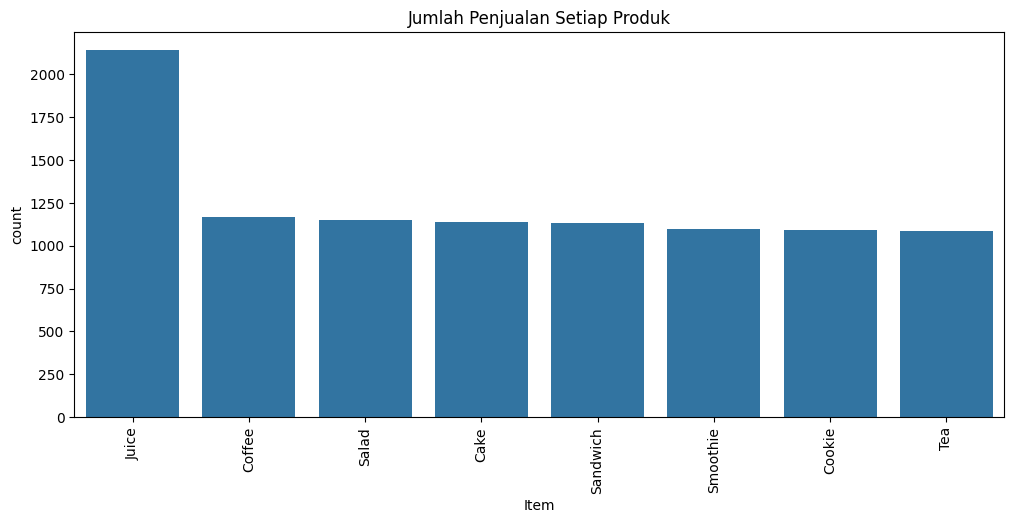

In [178]:
plt.figure(figsize=(12,5))

sns.countplot(
    data=df,
    x="Item",
    order=df["Item"].value_counts().index
)

plt.xticks(rotation=90)

plt.title("Jumlah Penjualan Setiap Produk")

plt.show()
# Produk apa yang paling sering dibeli
# juice merupakan produk yang paling banyak terjual sehingga menjadi produk utama café.

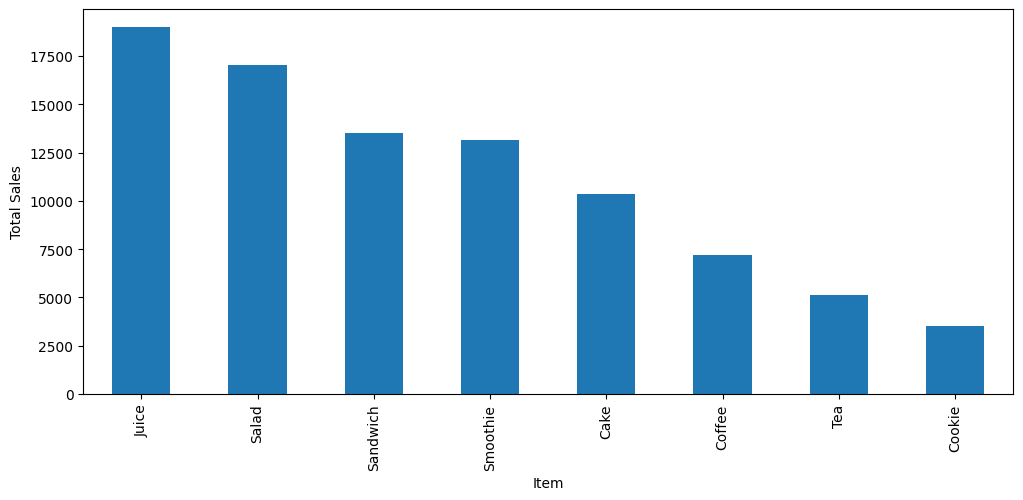

In [179]:
sales=df.groupby("Item")["Total Spent"].sum().sort_values(ascending=False)

plt.figure(figsize=(12,5))

sales.plot(kind="bar")

plt.ylabel("Total Sales")

plt.show()
#Total Pendapatan Setiap Produk

**Insight 1 (Deskriptif)**

Berdasarkan grafik Total Penjualan per Produk, Juice merupakan produk dengan total penjualan tertinggi, diikuti oleh Salad dan Sandwich. Sebaliknya, Cookie memiliki total penjualan terendah dibandingkan produk lainnya.

**Insight 2 (Analisis Bisnis)**

Tingginya total penjualan pada produk Juice menunjukkan bahwa produk tersebut memiliki permintaan yang tinggi dan menjadi salah satu sumber pendapatan utama bagi café. Oleh karena itu, pihak café perlu memastikan ketersediaan stok bahan baku Juice agar dapat memenuhi permintaan pelanggan secara konsisten.

**Insight 3 (Rekomendasi)**

Produk seperti Tea dan Cookie memiliki total penjualan yang relatif rendah. Café dapat mempertimbangkan strategi promosi, seperti memberikan paket bundling antara Coffee dan Cookie atau Tea dan Cake, untuk meningkatkan penjualan kedua produk tersebut.

Analisis Total Penjualan Berdasarkan Produk

Grafik menunjukkan bahwa Juice menjadi produk dengan total penjualan tertinggi, disusul oleh Salad, Sandwich, dan Smoothie. Hal ini mengindikasikan bahwa pelanggan lebih banyak membeli minuman segar dan makanan ringan sebagai pilihan utama. Sebaliknya, Cookie merupakan produk dengan total penjualan terendah, sehingga perlu dilakukan evaluasi terhadap strategi pemasaran maupun daya tarik produk tersebut.

Dari sisi bisnis, produk dengan penjualan tinggi seperti Juice perlu diprioritaskan dalam pengelolaan stok agar tidak terjadi kehabisan persediaan. Sementara itu, produk dengan penjualan rendah dapat ditingkatkan melalui promosi, diskon, atau paket bundling dengan produk yang lebih populer guna meningkatkan nilai penjualan.

"Apa insight dari grafik ini?"

Anda bisa menjawab:

"Grafik menunjukkan bahwa Juice merupakan produk dengan total penjualan tertinggi sehingga menjadi kontributor utama pendapatan café. Sebaliknya, Cookie memiliki penjualan paling rendah sehingga perlu dievaluasi melalui strategi promosi atau bundling agar penjualannya meningkat. Dari hasil ini, saya merekomendasikan agar pihak café memprioritaskan stok Juice dan melakukan pemasaran khusus untuk produk dengan penjualan rendah."

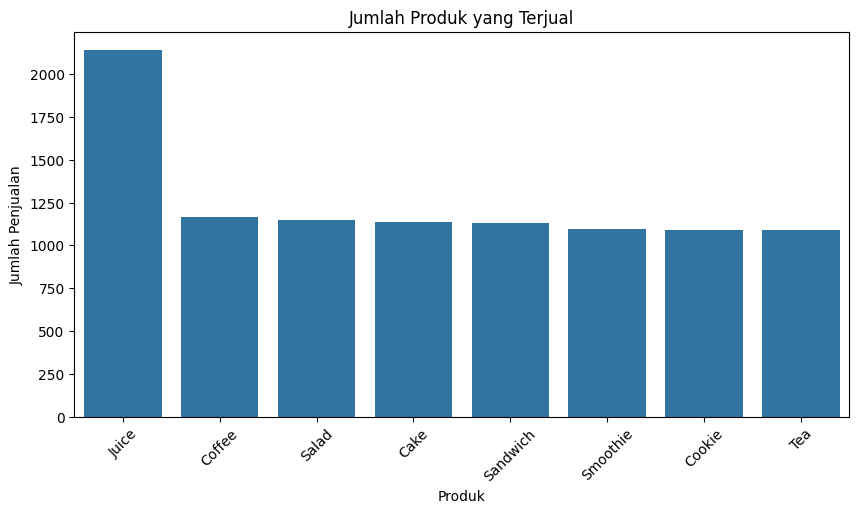

In [180]:
item_count = df["Item"].value_counts()

plt.figure(figsize=(10,5))

ax = sns.barplot(
    x=item_count.index,
    y=item_count.values
)

plt.title("Jumlah Produk yang Terjual")
plt.xlabel("Produk")
plt.ylabel("Jumlah Penjualan")

plt.xticks(rotation=45)

plt.show()

Insight

Misalnya

Juice menjadi produk yang paling sering dibeli pelanggan, sedangkan Cookie merupakan produk dengan frekuensi pembelian terendah.

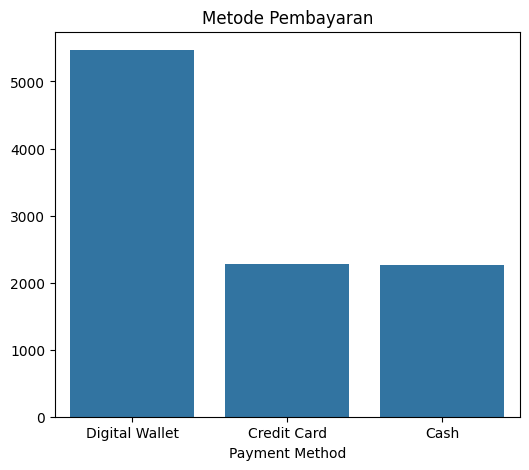

In [181]:
payment = df["Payment Method"].value_counts()

plt.figure(figsize=(6,5))

sns.barplot(
    x=payment.index,
    y=payment.values
)

plt.title("Metode Pembayaran")

plt.show()

Insight

Misalnya

Mayoritas pelanggan menggunakan pembayaran Cash dibandingkan metode lainnya.

Rekomendasi

Kasir perlu memastikan ketersediaan uang kembalian karena transaksi tunai masih mendominasi.

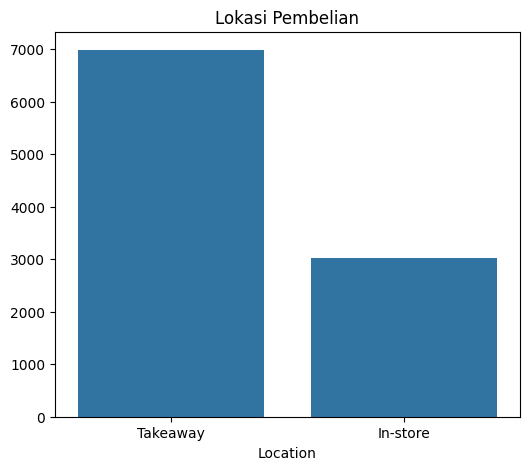

In [182]:
location = df["Location"].value_counts()

plt.figure(figsize=(6,5))

sns.barplot(
    x=location.index,
    y=location.values
)

plt.title("Lokasi Pembelian")

plt.show()

Insight

Misalnya

Pelanggan lebih banyak membeli secara Takeaway dibandingkan In-store.

Rekomendasi

Café dapat meningkatkan layanan Takeaway agar proses pelayanan menjadi lebih cepat.

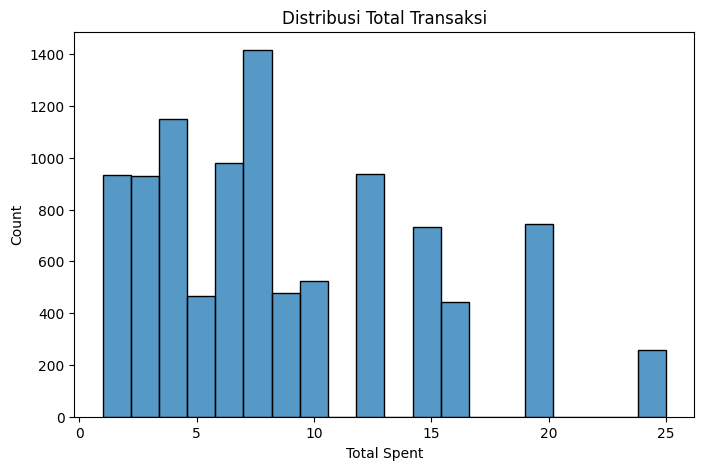

In [183]:
plt.figure(figsize=(8,5))

sns.histplot(df["Total Spent"], bins=20)

plt.title("Distribusi Total Transaksi")

plt.show()

Insight

Misalnya

Sebagian besar transaksi berada pada nominal rendah hingga menengah.

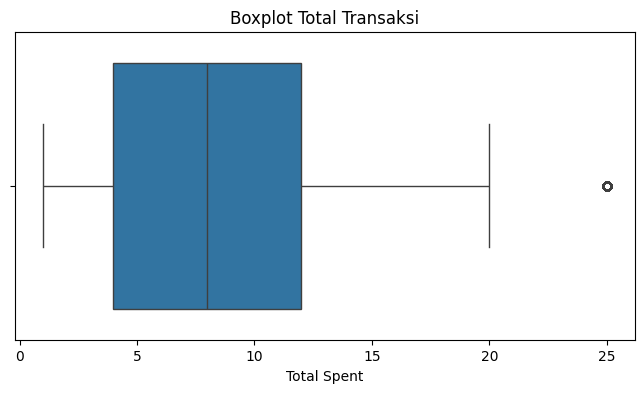

In [184]:
plt.figure(figsize=(8,4))

sns.boxplot(x=df["Total Spent"])

plt.title("Boxplot Total Transaksi")

plt.show()

Insight

Misalnya

Terdapat beberapa transaksi yang jauh lebih besar dibandingkan transaksi lainnya sehingga merupakan outlier.

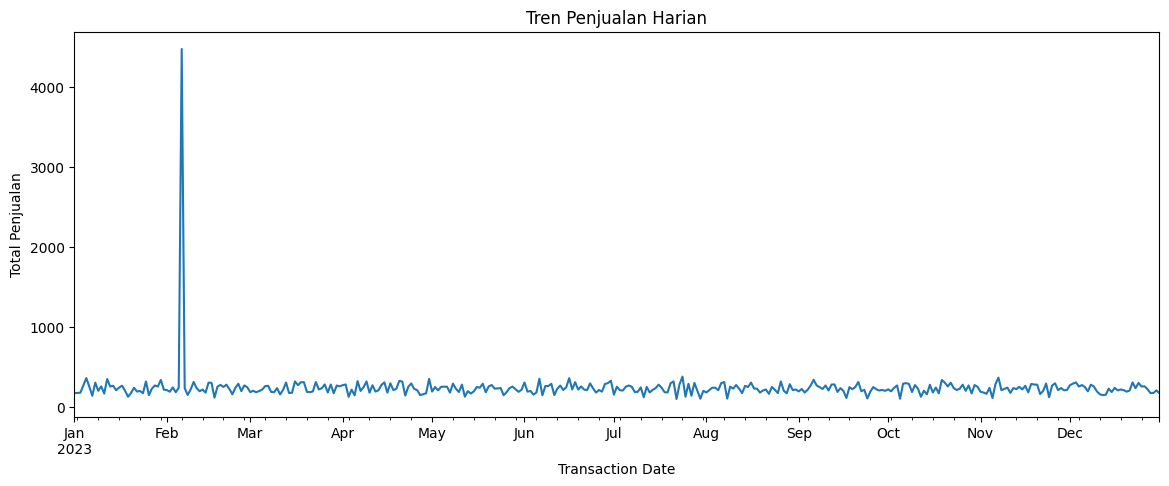

In [185]:
daily = df.groupby("Transaction Date")["Total Spent"].sum()

plt.figure(figsize=(14,5))

daily.plot()

plt.title("Tren Penjualan Harian")

plt.ylabel("Total Penjualan")

plt.show()

Insight

Misalnya

Penjualan mengalami fluktuasi sepanjang tahun 2023.

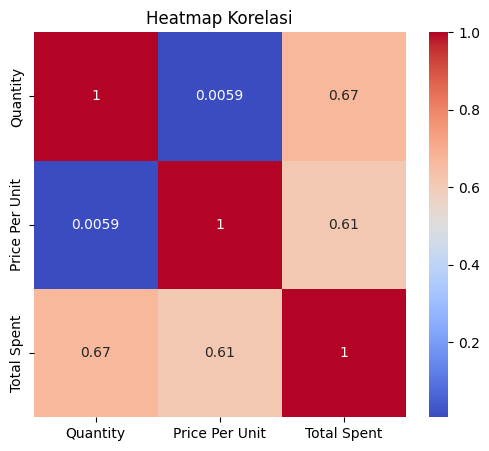

In [186]:
plt.figure(figsize=(6,5))

sns.heatmap(
    df.select_dtypes("number").corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Heatmap Korelasi")

plt.show()

Insight

Misalnya

Quantity memiliki korelasi positif yang kuat dengan Total Spent, menunjukkan bahwa semakin banyak jumlah produk yang dibeli pelanggan, semakin besar total nilai transaksi.

In [187]:
df.to_csv("clean_cafe_sales.csv", index=False)